In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 89.0 MB/s eta 0:00:00


STEP 1. Classical Data
Input Feature: [0.3 0.7]

STEP 2. Feature Map


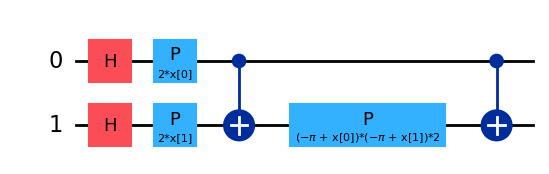

STEP 3. Variational Circuit


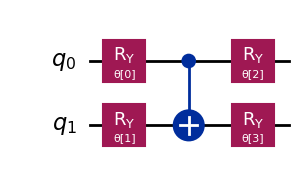

STEP 4. Compose Circuit


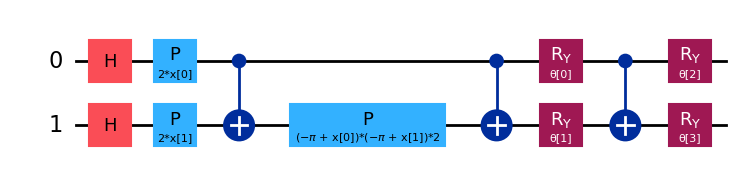

STEP 5. Measurement


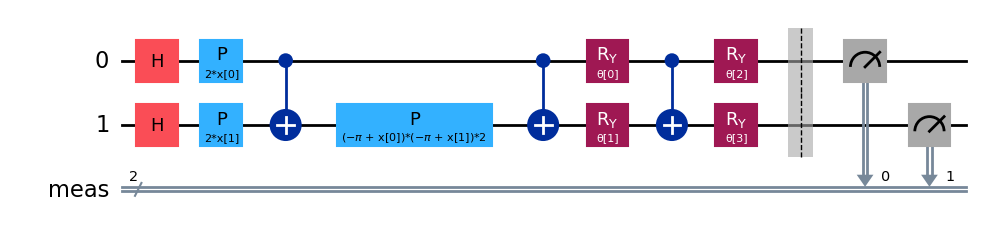

STEP 6. Parameter
Parameter List:
x[0]
x[1]
θ[0]
θ[1]
θ[2]
θ[3]

Parameter Count: 6

STEP 7. Parameter Binding
x[0]            -> 3.006
x[1]            -> 3.083
θ[0]            -> 1.371
θ[1]            -> 1.311
θ[2]            -> 1.623
θ[3]            -> 2.989

STEP 8. Simulation
Simulation Counts: {'01': 34, '11': 495, '00': 2, '10': 493}

STEP 9. Measurement Result (Histogram)


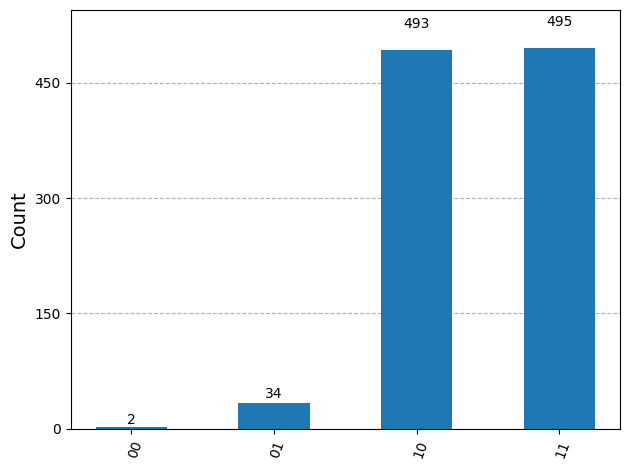

In [3]:
import numpy as np
from qiskit import transpile
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from IPython.display import display

# ======================================================
# STEP 1. Classical Data
# ======================================================
print("=" * 70)
print("STEP 1. Classical Data")
print("=" * 70)
x = np.array([0.3, 0.7])
print("Input Feature:", x)
print()

# ======================================================
# STEP 2. Feature Map 생성
# ======================================================
print("=" * 70)
print("STEP 2. Feature Map")
print("=" * 70)
feature_map = zz_feature_map(feature_dimension=2, reps=1)
display(feature_map.draw("mpl"))

# ======================================================
# STEP 3. Variational Circuit 생성 (Ansatz)
# ======================================================
print("=" * 70)
print("STEP 3. Variational Circuit")
print("=" * 70)
ansatz = real_amplitudes(num_qubits=2, reps=1)
display(ansatz.draw("mpl"))

# ======================================================
# STEP 4. Circuit 결합
# ======================================================
print("=" * 70)
print("STEP 4. Compose Circuit")
print("=" * 70)
qml_circuit = feature_map.compose(ansatz)
display(qml_circuit.draw("mpl"))

# ======================================================
# STEP 5. Measurement 추가
# ======================================================
print("=" * 70)
print("STEP 5. Measurement")
print("=" * 70)
qml_circuit.measure_all()
display(qml_circuit.draw("mpl"))

# ======================================================
# STEP 6. Parameter 확인
# ======================================================
print("=" * 70)
print("STEP 6. Parameter")
print("=" * 70)
print("Parameter List:")
for p in qml_circuit.parameters:
    print(p)
print("\nParameter Count:", len(qml_circuit.parameters))
print()

# ======================================================
# STEP 7. Parameter Binding
# ======================================================
print("=" * 70)
print("STEP 7. Parameter Binding")
print("=" * 70)
parameter_values = {}
for p in qml_circuit.parameters:
    value = np.random.uniform(0, np.pi)
    parameter_values[p] = value
    print(f"{p!s:15} -> {value:.3f}")

print()
bound_circuit = qml_circuit.assign_parameters(parameter_values)

# ======================================================
# STEP 8. Simulator 실행
# ======================================================
print("=" * 70)
print("STEP 8. Simulation")
print("=" * 70)
simulator = AerSimulator()
compiled = transpile(bound_circuit, simulator)
job = simulator.run(compiled, shots=1024)
result = job.result()
counts = result.get_counts()
print("Simulation Counts:", counts)
print()

# ======================================================
# STEP 9. Histogram
# ======================================================
print("=" * 70)
print("STEP 9. Measurement Result (Histogram)")
print("=" * 70)
fig_hist = plot_histogram(counts)
display(fig_hist)